In [1]:
#imports
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# fix the random seeds so the results can be reproduced
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [2]:
#settings & data paths
train_dir = "chest_xray/train"
test_dir  = "chest_xray/test"

IMG_SIZE = 224 #224x224 pixels is standard for deeplearning
BATCH_SIZE = 32 # a good number to run on cpu, if using gpu, double it

In [3]:
# TRAIN images: normalize + augmentation (random rotations/zoom/flips help the model generalize)
train_datagen = ImageDataGenerator(rescale=1./255,
                                   rotation_range=15,
                                   zoom_range=0.1,
                                   horizontal_flip=True,
                                   validation_split=0.2)

# VALIDATION images: normalize ONLY, no augmentation,
# so the validation score reflects real, undistorted X-rays (same as the test set)
val_datagen = ImageDataGenerator(rescale=1./255,
                                 validation_split=0.2)

train = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="training",
    seed=SEED)

val = val_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation",
    shuffle=False,
    seed=SEED)

# same validation_split + same folder => both generators use the same 80/20 split,
# so no validation image is ever used for training
print(train.class_indices)

Found 4173 images belonging to 2 classes.
Found 1043 images belonging to 2 classes.
{'NORMAL': 0, 'PNEUMONIA': 1}


In [4]:
#how many images we have in the training data set (classified)
import os
for cls in ["NORMAL", "PNEUMONIA"]:
    n = len(os.listdir(f"{train_dir}/{cls}"))
    print(cls, n)

NORMAL 1341
PNEUMONIA 3875


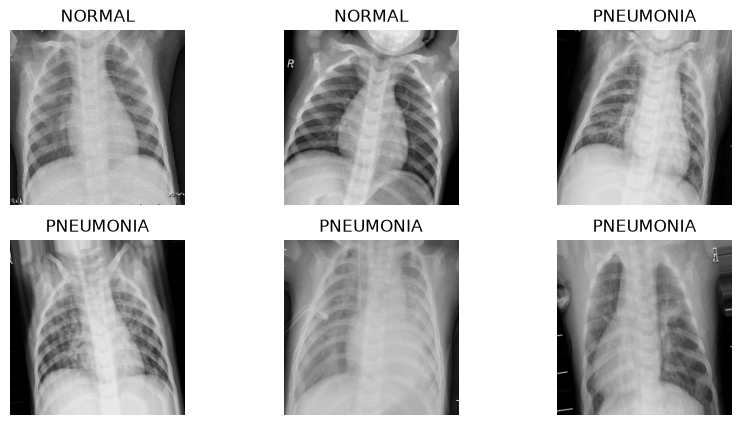

In [5]:
images, labels = next(train) # grab one batch of images + their labels from the train loader (32 photos)

plt.figure(figsize=(10, 5)) # create the overall figure, 10x5 inches in size

for i in range(6): # loop 6 times, to show 6 images
    plt.subplot(2, 3, i+1)   # place image in a 2-row x 3-col grid, at slot i+1
    plt.imshow(images[i])  # draw the i-th image
    plt.title("PNEUMONIA" if labels[i]==1 else "NORMAL")  # title = correct label (1=PNEUMONIA, 0=NORMAL)
    plt.axis("off") # hide the x/y axis ticks (cleaner look)
plt.show() # render everything on screen

In [6]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Conv2D(32, (3,3), activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, (3,3), activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

In [7]:
model.compile(optimizer="adam",
              loss="binary_crossentropy",
              metrics=["accuracy"])

history = model.fit(train,
                    validation_data=val,
                    epochs=5)
                    

Epoch 1/5














In [8]:
# load the test images (normalize only — NO augmentation, we don't distort exam data)
test_datagen = ImageDataGenerator(rescale=1./255)

test = test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False)               # keep order fixed so predictions line up with true labels

# the real test: score the model on images it has NEVER seen
loss, accuracy = model.evaluate(test)
print("Test accuracy:", accuracy)

Found 624 images belonging to 2 classes.














## Test-set metrics beyond accuracy

The dataset is imbalanced (~74% PNEUMONIA), and in a medical task a **missed pneumonia case (false negative)** is the most dangerous error.
So below I report the **confusion matrix** and **precision / recall / F1** per class on the test set.




















20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 78ms/step


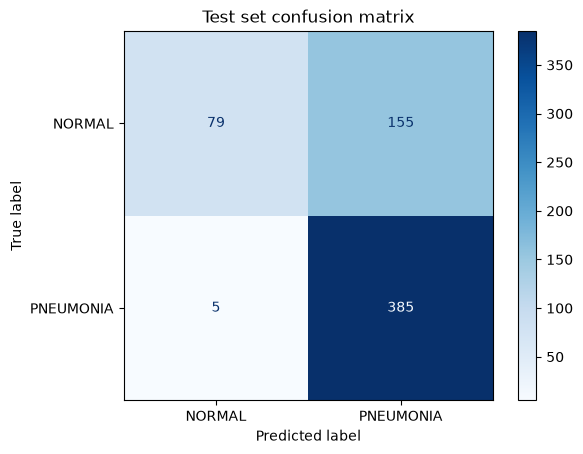

              precision    recall  f1-score   support
      NORMAL      0.940     0.338     0.497       234
   PNEUMONIA      0.713     0.987     0.828       390
    accuracy                          0.744       624
   macro avg      0.827     0.662     0.662       624
weighted avg      0.798     0.744     0.704       624
Pneumonia recall (sensitivity): 0.987  -> missed 5 of 390 pneumonia cases
Normal recall (specificity):    0.338  -> 155 of 234 healthy patients flagged


In [9]:
# predicted probability of PNEUMONIA for every test image (order matches test.classes because shuffle=False)
probs = model.predict(test).ravel()
preds = (probs >= 0.5).astype(int)
y_true = test.classes
labels = list(test.class_indices.keys())   # ['NORMAL', 'PNEUMONIA']

cm = confusion_matrix(y_true, preds)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues", values_format="d")
plt.title("Test set confusion matrix")
plt.show()

print(classification_report(y_true, preds, target_names=labels, digits=3))

tn, fp, fn, tp = cm.ravel()
print(f"Pneumonia recall (sensitivity): {tp/(tp+fn):.3f}  -> missed {fn} of {tp+fn} pneumonia cases")
print(f"Normal recall (specificity):    {tn/(tn+fp):.3f}  -> {fp} of {tn+fp} healthy patients flagged")

## Conclusion & Interpretation

**Results (after the review fixes).** I built a CNN from scratch to classify chest X-rays as NORMAL or PNEUMONIA. Validation now uses its own generator with **no augmentation**, so the validation score reflects real images. The model reached **92.0% validation accuracy** but **74.4% test accuracy**. This gap is a known characteristic of this dataset: the test set is distributed differently from the training data (for example, it has a much higher share of NORMAL images: 38% vs 26%). Validation scores taken from the training folder are optimistic.

**Test-set metrics beyond accuracy.**

| Class | Precision | Recall | F1 |
|---|---|---|---|
| PNEUMONIA | 0.713 | **0.987** | 0.828 |
| NORMAL | 0.940 | 0.338 | 0.497 |

- **Pneumonia recall (sensitivity) is 98.7%:** the model missed only 5 of 390 pneumonia cases. For a screening tool this is the most important number, because a missed case (false negative) is the most dangerous error.
- **Normal recall (specificity) is only 33.8%:** 155 of 234 healthy patients were flagged as pneumonia. The model is biased towards "pneumonia", which is what you'd expect from training data that is 74% pneumonia. In practice that means many unnecessary follow-up checks.
- So the 74% accuracy hides a very lopsided model, which is exactly why accuracy alone isn't enough for a medical task.

**Ethical considerations.** A model like this should be treated as a decision-support tool, not a replacement for a radiologist. Real risks include: the model learning shortcuts from a specific hospital's equipment rather than true pathology, degraded performance on populations not represented in the training data, and the danger of over-trusting an automated output. Any real deployment would require validation across diverse hospitals, clinician oversight, and clear accountability.

**Next steps.** Use **class weights** (or oversample NORMAL) to fix the bias towards pneumonia, **tune the decision threshold** (0.5 is not necessarily best) on validation data, try **transfer learning** (e.g. MobileNetV2 or DenseNet121), and add **EarlyStopping** on validation loss.

**Conclusion.** This project demonstrates a full deep learning pipeline (data exploration, preprocessing, augmentation on training data only, model building, and honest evaluation with a confusion matrix and per-class recall) while staying realistic about the limits of AI in healthcare.